# Assignment 1 (Week 5) — Motor parameter identification

**CS413 Robotics, NewUU** · Fayozbek Yusupov · Student ID: 240061

I identify the parameters of the two drive motors of my TRIK robot from my own measurements. The data were recorded with two TRIK Studio block programs (`motor_steps.qrs`, `motor_signal.qrs`), and the raw files are in `motor_data/`.

## 1. Motor model

If the armature inductance is neglected, a lightly loaded DC motor is a first-order system:

$$\frac{d\omega}{dt} = \frac{U}{T_m k_e} - \frac{\omega}{T_m}, \qquad \frac{d\theta}{dt} = \omega$$

| Symbol | Meaning (my words) | Unit |
|---|---|---|
| $U$ | voltage on the motor, $U = \text{PWM}/100 \cdot U_{battery}$ | V |
| $\theta$, $\omega$ | angle of the wheel and how fast it turns | rad, rad/s |
| $\omega_{ss}$ | the constant speed the motor reaches at a fixed $U$ | rad/s |
| $T_m$ | how fast the motor speeds up: after $T_m$ seconds it has 63 % of $\omega_{ss}$ | s |
| $k_e$ | how many volts are needed for 1 rad/s of steady speed | V·s/rad |

**Step response.** At $t=0$ a constant $U$ is applied to a motor at rest. With $\omega_{ss}=U/k_e$ the equation is $T_m\dot\omega + \omega = \omega_{ss}$. Its solution is $Ce^{-t/T_m}$ plus the constant $\omega_{ss}$, and $\omega(0)=0$ gives $C=-\omega_{ss}$:

$$\omega(t) = \omega_{ss}\left(1 - e^{-t/T_m}\right)$$

The angle is the integral of the speed:

$$\theta(t) = \int_0^t \omega_{ss}\left(1 - e^{-s/T_m}\right)ds = \omega_{ss}\left(t - T_m + T_m e^{-t/T_m}\right)$$

For large $t$ this is a straight line with slope $\omega_{ss}$, shifted by $T_m$, so one step gives both numbers.

**Assumptions** (each one is checked with my data):

* no inductance: no delay or overshoot at the start of a step (sec. 4.2);
* linear viscous friction: $\omega_{ss}$ proportional to $U$ and no dead zone (sec. 4.3);
* constant load: the same $T_m$ at all speeds and in both directions (sec. 4.3);
* constant battery voltage: the same PWM gives the same speed early and late (sec. 5).

## 2. Test signals

| Signal | Why |
|---|---|
| Steps −100 … +100 % (step 10 %), 2 s on + 1 s off | $\omega_{ss}$ and $T_m$ at every level, asymmetry, saturation, coasting |
| Fine steps −9 … +9 % (step 1 %) | the dead zone: at 10 % both wheels already turn |
| Square wave, 60 %, period 1 s, 8 s | fast direction reversals, backlash, $T_m$ in both directions |
| Chirp, 60 %, 0.2 → 5 Hz in 8 s | frequency response, a direct check of $T_m$ |

The period of 1 s is several times $T_m$, the chirp passes $1/(2\pi T_m)$ (about 0.8–1 Hz), both signals cross zero, and 60 % is below 80 %.

## 3. Data collection

Both programs are made only of blocks. `motor_steps.qrs` logs 3 s with the motor off, then every level for 2 s and 1 s of coasting after it (for the fine series only the start and the step of `level` were changed). `motor_signal.qrs` recalculates the PWM from the formula in every cycle (`kind = 1` square, `kind = 4` chirp); TRIK Studio has no `round()`, so I used `floor(u + 0.5)`. Every line of a file is `angle, time, PWM`.

* Left motor M4 with encoder E4, right motor M3 with encoder E3. For M3 only the ports and the file name were changed.
* The robot was held in the air, so the wheels spun freely. The step series was run twice on M4.
* The timer is 5 ms in all loops; the real interval is longer because of the file writing (sec. 5).
* The battery showed 11.2 V before and after every run (`motor_data/battery.txt`).

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint

if not os.path.exists('motor_data'):
    os.system('git clone https://github.com/KINGLABBOK/CS413-Robotics.git')
    os.chdir('CS413-Robotics/Assignment1')

## 4. Data processing

### 4.1 Loading

The columns of my files are angle (degrees), time (ms) and PWM (%), so the loading line of the course notebook is changed to this order. Angle is converted to rad and time to s.

In [2]:
def load(name):
    angle, t, pwm = np.loadtxt('motor_data/' + name, delimiter=',', unpack=True)
    return angle * np.pi / 180, t / 1000, pwm

print(open('motor_data/battery.txt').read())
U_bat = 11.2

# Battery voltage read on the TRIK display before and after each run (display resolution 0.1 V)
file,before_V,after_V
steps_M4.txt,11.2,11.2
steps_M4_repeat.txt,11.2,11.2
steps_M3.txt,11.2,11.2
square_M4.txt,11.2,11.2
square_M3.txt,11.2,11.2
chirp_M4.txt,11.2,11.2
chirp_M3.txt,11.2,11.2
deadzone_M4.txt,11.2,11.2
deadzone_M3.txt,11.2,11.2



### 4.2 Step responses

For every PWM level I take the part of the file with this PWM, start its angle and time from zero and fit the model of the course notebook with `curve_fit`. The bounds keep $T_m$ positive (without them the fit at ±100 % fails). In the fine series a level counts as "not moving" if the wheel turned less than 10° in 2 s, and the speed is the slope of the last second.

In [3]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)

levels = [l for l in range(-100, 101, 10) if l != 0]
fine_levels = [l for l in range(-9, 10) if l != 0]

def cut(name, level):
    angle, t, pwm = load(name)
    i = np.where(pwm == level)[0]
    return t[i] - t[i[0]], angle[i] - angle[i[0]]

def fit_steps(name):
    rows = []
    for level in levels:
        ts, th = cut(name, level)
        popt, pcov = optimize.curve_fit(model, ts, th, p0=[8 * np.sign(level), 0.1],
                                        bounds=([-60, 0.005], [60, 2]))
        err = np.sqrt(np.diag(pcov))
        rows.append([popt[0], err[0], popt[1], err[1]])
    return np.array(rows).T

def fit_fine(name):
    w = []
    for level in fine_levels:
        ts, th = cut(name, level)
        if abs(th[-1]) > np.radians(10):
            w.append(np.polyfit(ts[ts > 1], th[ts > 1], 1)[0])
        else:
            w.append(0.0)
    return np.array(w)

steps = {'M4': fit_steps('steps_M4.txt'), 'M4 repeat': fit_steps('steps_M4_repeat.txt'), 'M3': fit_steps('steps_M3.txt')}
fine = {'M4': fit_fine('deadzone_M4.txt'), 'M3': fit_fine('deadzone_M3.txt')}

for k in ['M4', 'M3']:
    w, w_err, T, T_err = steps[k]
    print(k)
    print('  PWM %   w_ss, rad/s        T_m, s')
    for j in range(len(levels)):
        print(f'  {levels[j]:5d}   {w[j]:7.2f} ± {w_err[j]:.3f}   {T[j]:.3f} ± {T_err[j]:.3f}')
    print('  fine series, w_ss in rad/s (0 = not moving):')
    print('  ' + '  '.join(f'{l:+d}%: {v:.2f}' for l, v in zip(fine_levels, fine[k])))

M4
  PWM %   w_ss, rad/s        T_m, s
   -100    -13.95 ± 0.004   0.045 ± 0.000
    -90    -12.62 ± 0.003   0.076 ± 0.000
    -80    -11.50 ± 0.003   0.113 ± 0.000
    -70    -10.29 ± 0.009   0.085 ± 0.001
    -60     -9.24 ± 0.008   0.152 ± 0.001
    -50     -8.37 ± 0.005   0.190 ± 0.001
    -40     -7.67 ± 0.004   0.202 ± 0.001
    -30     -6.23 ± 0.005   0.231 ± 0.001
    -20     -4.98 ± 0.004   0.307 ± 0.001
    -10     -3.38 ± 0.004   0.352 ± 0.001
     10      3.93 ± 0.004   0.292 ± 0.001
     20      5.63 ± 0.005   0.269 ± 0.001
     30      6.80 ± 0.014   0.058 ± 0.002
     40      8.46 ± 0.006   0.206 ± 0.001
     50      9.23 ± 0.006   0.201 ± 0.001
     60     10.10 ± 0.015   0.097 ± 0.002
     70     11.29 ± 0.007   0.136 ± 0.001
     80     12.56 ± 0.005   0.111 ± 0.000
     90     13.80 ± 0.005   0.075 ± 0.000
    100     15.29 ± 0.003   0.048 ± 0.000
  fine series, w_ss in rad/s (0 = not moving):
  -9%: -2.09  -8%: -2.25  -7%: -2.22  -6%: -2.12  -5%: -1.24  -4%: 0.00  -

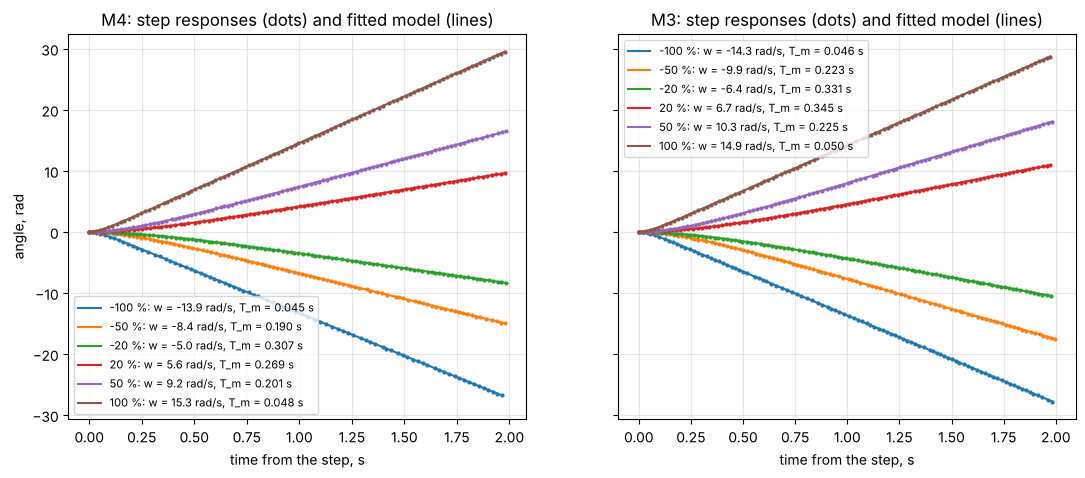

In [4]:
show = [-100, -50, -20, 20, 50, 100]
fig, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, k, name in [(axs[0], 'M4', 'steps_M4.txt'), (axs[1], 'M3', 'steps_M3.txt')]:
    w, w_err, T, T_err = steps[k]
    for level in show:
        j = levels.index(level)
        ts, th = cut(name, level)
        line, = ax.plot(ts, th, '.', ms=4)
        ax.plot(ts, model(ts, w[j], T[j]), '-', color=line.get_color(),
                label=f'{level} %: w = {w[j]:.1f} rad/s, T_m = {T[j]:.3f} s')
    ax.set_title(k + ': step responses (dots) and fitted model (lines)')
    ax.set_xlabel('time from the step, s')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axs[0].set_ylabel('angle, rad')
plt.show()

### 4.3 Speed and time constant versus PWM

For each motor and direction I fit a straight line $|\omega_{ss}| = a\,|\text{PWM}| + b$ where it is linear, $|\text{PWM}| \ge 30\%$. With $U = \text{PWM}/100 \cdot U_{battery}$ the slope gives $k_e = U_{battery}/(100\,a)$. The dead zone is the fine levels where the wheel did not move.

In [5]:
par = {}
for k in ['M4', 'M4 repeat', 'M3']:
    w, w_err, T, T_err = steps[k]
    wf = fine[k.split()[0]]
    for direction, sign in [('forward', 1), ('backward', -1)]:
        j = [n for n in range(len(levels)) if np.sign(levels[n]) == sign]
        lv = np.abs(np.array(levels)[j])
        ws = np.abs(w[j])
        Ts = T[j]
        a, b = np.polyfit(lv[lv >= 30], ws[lv >= 30], 1)
        stuck = [abs(l) for l, v in zip(fine_levels, wf) if np.sign(l) == sign and v == 0]
        dz = max(stuck) if stuck else 0
        par[k, direction] = dict(lv=lv, w=ws, T=Ts, a=a, b=b, k_e=U_bat / (100 * a), dz=dz,
                                 T_mean=Ts.mean(), T_std=Ts.std())

print('motor      direction  dead zone  moves from  slope a, rad/s per %  b, rad/s  k_e, V*s/rad  mean T_m, s')
for (k, direction), p in par.items():
    dz = f"1..{p['dz']} %" if p['dz'] else 'none'
    print(f"{k:10s} {direction:9s}  {dz:9s}  {p['dz'] + 1:3d} %       {p['a']:.4f}                {p['b']:5.2f}"
          f"     {p['k_e']:.3f}         {p['T_mean']:.3f} ± {p['T_std']:.3f}")

motor      direction  dead zone  moves from  slope a, rad/s per %  b, rad/s  k_e, V*s/rad  mean T_m, s
M4         forward    none         1 %       0.1157                 3.42     0.968         0.149 ± 0.083
M4         backward   1..4 %       5 %       0.1062                 3.08     1.054         0.175 ± 0.096
M4 repeat  forward    none         1 %       0.1148                 3.55     0.976         0.179 ± 0.081
M4 repeat  backward   1..4 %       5 %       0.1086                 2.90     1.031         0.168 ± 0.118
M3         forward    none         1 %       0.0940                 5.54     1.191         0.207 ± 0.108
M3         backward   none         1 %       0.0915                 5.21     1.224         0.193 ± 0.108


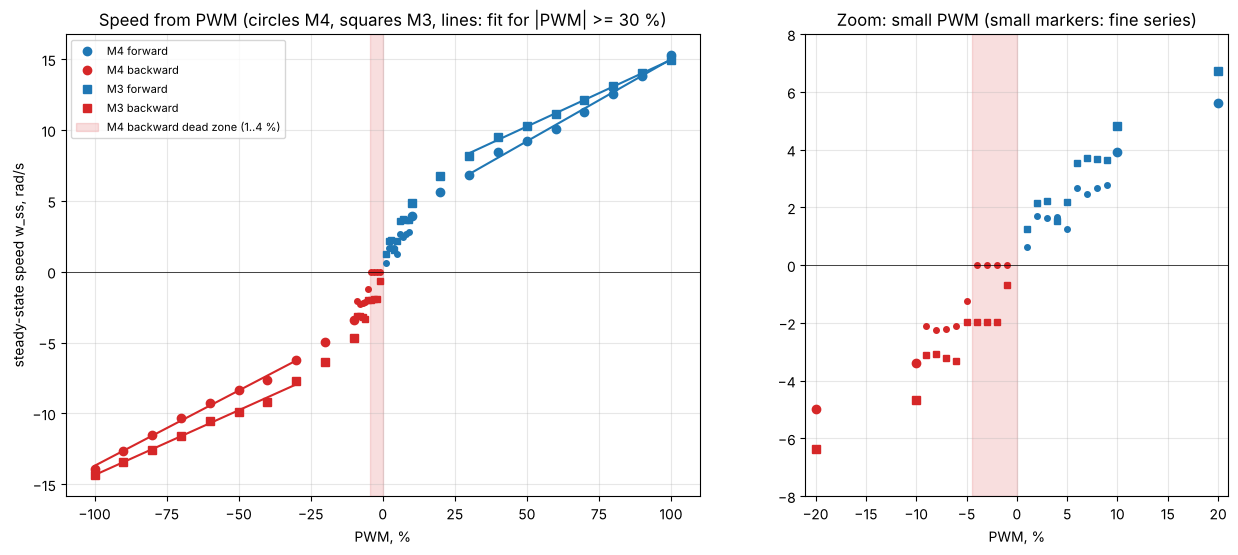

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [3, 2]})
for k, mark in [('M4', 'o'), ('M3', 's')]:
    for direction, sign, color in [('forward', 1, 'tab:blue'), ('backward', -1, 'tab:red')]:
        p = par[k, direction]
        fl = [abs(l) for l in fine_levels if np.sign(l) == sign]
        fw = [abs(v) for l, v in zip(fine_levels, fine[k]) if np.sign(l) == sign]
        for ax in (ax1, ax2):
            ax.plot(sign * p['lv'], sign * p['w'], mark, color=color, label=f'{k} {direction}')
            ax.plot(sign * np.array(fl), sign * np.array(fw), mark, ms=4, color=color)
        x = np.array([30, 100])
        ax1.plot(sign * x, sign * (p['a'] * x + p['b']), '-', color=color)
dz = par['M4', 'backward']['dz']
for ax in (ax1, ax2):
    ax.axvspan(-dz - 0.5, 0, color='tab:red', alpha=0.15, label=f'M4 backward dead zone (1..{dz} %)')
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xlabel('PWM, %')
    ax.grid(alpha=0.3)
ax1.set_ylabel('steady-state speed w_ss, rad/s')
ax1.set_title('Speed from PWM (circles M4, squares M3, lines: fit for |PWM| >= 30 %)')
ax1.legend(fontsize=8)
ax2.set_xlim(-21, 21)
ax2.set_ylim(-8, 8)
ax2.set_title('Zoom: small PWM (small markers: fine series)')
plt.show()

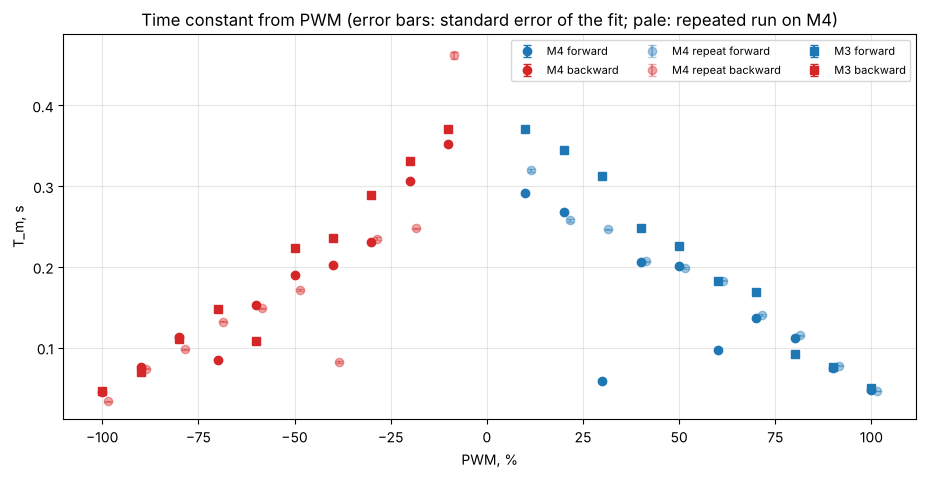

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
for k, mark, alpha in [('M4', 'o', 1), ('M4 repeat', 'o', 0.4), ('M3', 's', 1)]:
    w, w_err, T, T_err = steps[k]
    shift = 1.5 if k == 'M4 repeat' else 0
    for direction, sign, color in [('forward', 1, 'tab:blue'), ('backward', -1, 'tab:red')]:
        j = [n for n in range(len(levels)) if np.sign(levels[n]) == sign]
        ax.errorbar(np.array(levels)[j] + shift, T[j], yerr=T_err[j], fmt=mark, color=color,
                    alpha=alpha, capsize=3, label=f'{k} {direction}')
ax.set_xlabel('PWM, %')
ax.set_ylabel('T_m, s')
ax.set_title('Time constant from PWM (error bars: standard error of the fit; pale: repeated run on M4)')
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=3)
plt.show()

### 4.4 Complex signals: model versus real motor

I simulate the motor with the recorded input. In the course notebook `u` is a constant; here it is interpolated from the logged PWM (in volts). Both models use $\dot\omega = (\omega_{ss}(U) - \omega)/T_m$ with the mean $T_m$ of the motor:

* **Model A (no dead zone):** $\omega_{ss} = U/k_e$ with one $k_e$ (mean of both directions), as in the course notebook.
* **Model B (dead zone + line of each direction):** $\omega_{ss}$ follows the fitted line of each direction, and the motor does not move inside the dead zone.

The measured speed is `np.gradient` of the angle smoothed with a moving average of **5 samples** (≈ 0.14 s); the simulated speed is smoothed the same way.

In [8]:
WINDOW = 5

def smooth(x):
    return np.convolve(x, np.ones(WINDOW) / WINDOW, mode='same')

def fit_percent(y, y_model):
    return 100 * (1 - np.linalg.norm(y - y_model) / np.linalg.norm(y - np.mean(y)))

def rmse(y, y_model):
    return np.sqrt(np.mean((y - y_model) ** 2))

def simulate(t_log, U_log, T_m, w_ss):
    def motor(state, t):
        speed, angle = state
        u = np.interp(t, t_log, U_log)
        return np.array([-speed / T_m + w_ss(u) / T_m, speed])
    y = odeint(motor, [0, 0], t_log)
    return y[:, 1], y[:, 0]

results = {}
print('signal          angle fit A / B      speed fit A / B      RMSE B: angle, rad   speed, rad/s')
for name in ['square_M4.txt', 'square_M3.txt', 'chirp_M4.txt', 'chirp_M3.txt']:
    k = name[-6:-4]
    f, b = par[k, 'forward'], par[k, 'backward']
    T_m = (f['T_mean'] + b['T_mean']) / 2
    k_e = (f['k_e'] + b['k_e']) / 2

    def model_A(u):
        return u / k_e

    def model_B(u):
        p = 100 * u / U_bat
        if p > f['dz'] + 0.5:
            return f['a'] * p + f['b']
        if p < -(b['dz'] + 0.5):
            return -(b['a'] * -p + b['b'])
        return 0.0

    angle, t, pwm = load(name)
    angle, t = angle - angle[0], t - t[0]
    U = pwm / 100 * U_bat
    thA, wA = simulate(t, U, T_m, model_A)
    thB, wB = simulate(t, U, T_m, model_B)
    w = smooth(np.gradient(angle, t))
    results[name] = dict(t=t, th=angle, w=w, pwm=pwm, U=U, thA=thA, wA=wA, thB=thB, wB=wB, T_m=T_m, k_e=k_e)
    print(f'{name:14s}  {fit_percent(angle, thA):6.1f} / {fit_percent(angle, thB):6.1f}      '
          f'{fit_percent(w, smooth(wA)):6.1f} / {fit_percent(w, smooth(wB)):6.1f}        '
          f'{rmse(angle, thB):6.2f}          {rmse(w, smooth(wB)):6.2f}')

signal          angle fit A / B      speed fit A / B      RMSE B: angle, rad   speed, rad/s
square_M4.txt    -98.4 /   53.6        67.5 /   90.9          0.57            0.50
square_M3.txt    -58.7 /   64.7        46.8 /   85.9          0.56            0.85
chirp_M4.txt    -130.8 /   -5.2        48.1 /   62.4          1.33            1.19


chirp_M3.txt    -138.7 /  -95.8        39.9 /   64.9          2.19            1.11


The plots below are for the left motor (M4); the fits of the right motor are in the table above.

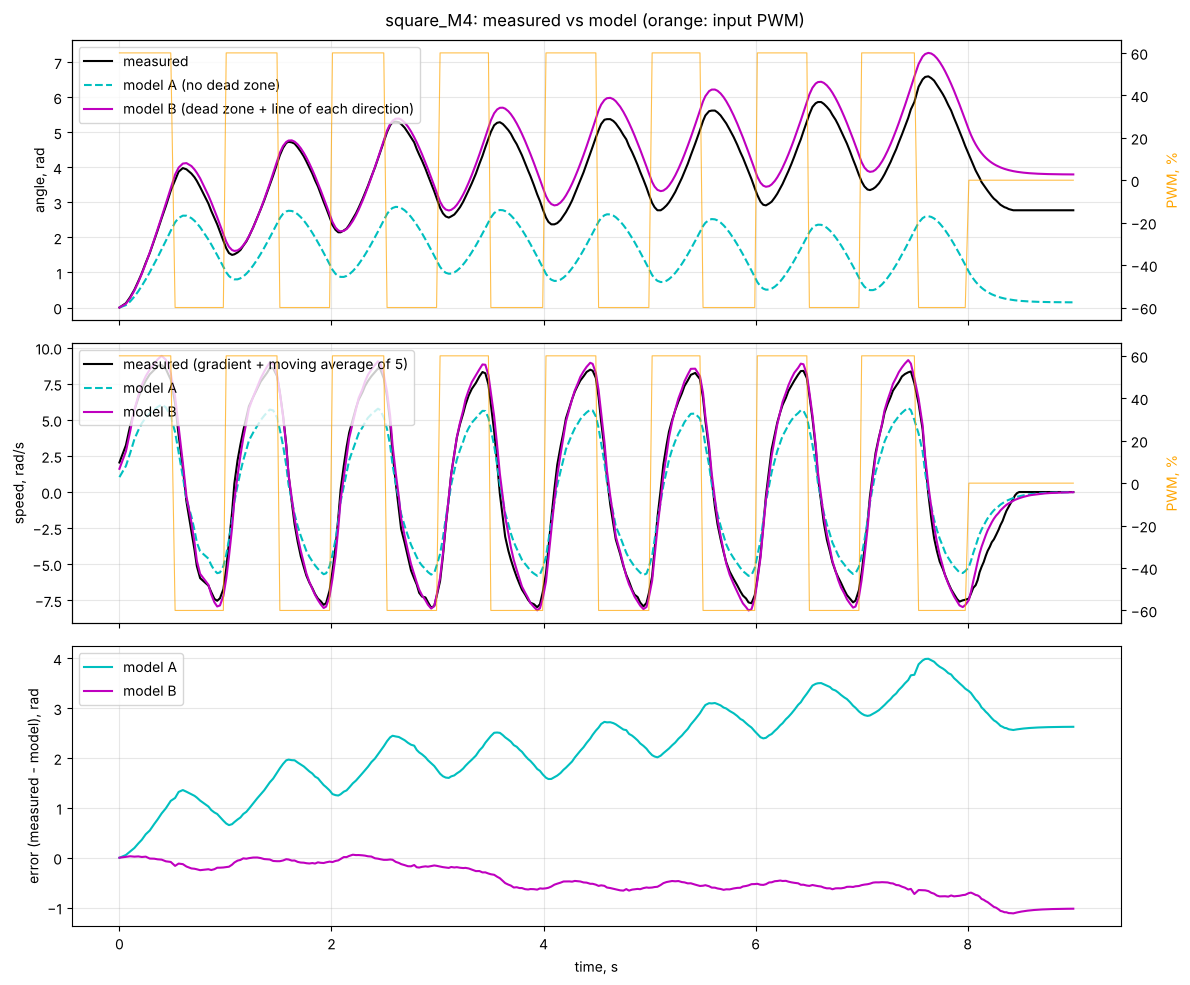

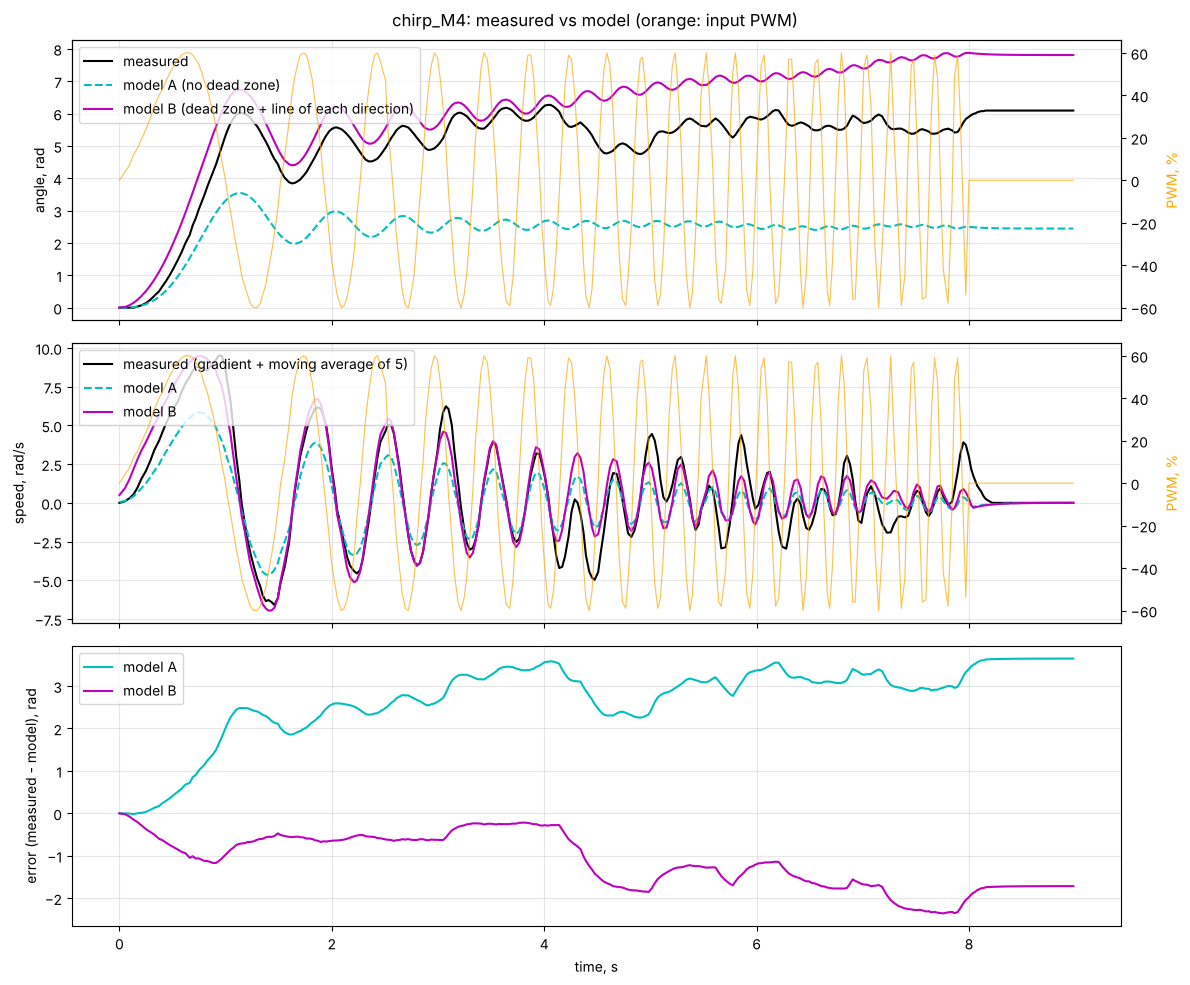

In [9]:
for name in ['square_M4.txt', 'chirp_M4.txt']:
    r = results[name]
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    ax1.plot(r['t'], r['th'], 'k-', lw=1.5, label='measured')
    ax1.plot(r['t'], r['thA'], 'c--', label='model A (no dead zone)')
    ax1.plot(r['t'], r['thB'], 'm-', label='model B (dead zone + line of each direction)')
    ax1.set_ylabel('angle, rad')
    ax2.plot(r['t'], r['w'], 'k-', lw=1.5, label='measured (gradient + moving average of 5)')
    ax2.plot(r['t'], smooth(r['wA']), 'c--', label='model A')
    ax2.plot(r['t'], smooth(r['wB']), 'm-', label='model B')
    ax2.set_ylabel('speed, rad/s')
    for ax in (ax1, ax2):
        ax.legend(loc='upper left')
        ax.grid(alpha=0.3)
        ax_pwm = ax.twinx()
        ax_pwm.plot(r['t'], r['pwm'], color='orange', lw=0.8, alpha=0.7)
        ax_pwm.set_ylabel('PWM, %', color='orange')
    ax3.plot(r['t'], r['th'] - r['thA'], 'c-', label='model A')
    ax3.plot(r['t'], r['th'] - r['thB'], 'm-', label='model B')
    ax3.set_ylabel('error (measured - model), rad')
    ax3.set_xlabel('time, s')
    ax3.legend(loc='upper left')
    ax3.grid(alpha=0.3)
    fig.suptitle(name[:-4] + ': measured vs model (orange: input PWM)')
    plt.tight_layout()
    plt.show()

**Chirp: frequency response.** I cut the chirp into single periods and in every period fit a sine wave $c_0 + c_1 t + a\sin(2\pi f t) + b\cos(2\pi f t)$ to the angle and to the input with `curve_fit`. The speed amplitude is $2\pi f\sqrt{a^2+b^2}$ of the angle fit, so I do not need to differentiate the noisy angle. The ratio speed amplitude / input amplitude is compared with $1/(k_e\sqrt{1+(2\pi f T_m)^2})$, once with $k_e$ from the slope and once with $k_e = U/\omega_{ss}$ at 60 %, the amplitude of the chirp.

M4: k_e from the slope 1.011, U/w_ss at 60 % 0.666 V*s/rad, mean T_m 0.162 s, 1/(2 pi T_m) = 0.98 Hz
M3: k_e from the slope 1.207, U/w_ss at 60 % 0.604 V*s/rad, mean T_m 0.200 s, 1/(2 pi T_m) = 0.79 Hz


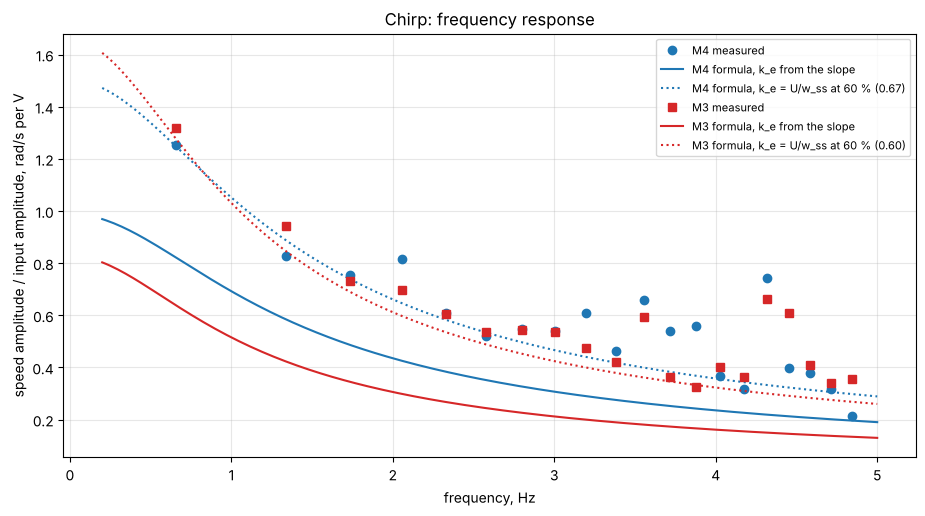

In [10]:
f0, f1, T_chirp = 0.2, 5.0, 8.0
rate = (f1 - f0) / T_chirp

def amplitudes(t, y):
    freqs, amps = [], []
    c = 0
    while True:
        t_a = (-f0 + np.sqrt(f0 ** 2 + 2 * rate * c)) / rate
        t_b = (-f0 + np.sqrt(f0 ** 2 + 2 * rate * (c + 1))) / rate
        if t_b > T_chirp:
            break
        m = (t >= t_a) & (t < t_b)
        f = 1 / (t_b - t_a)
        if m.sum() >= 5:
            sine = lambda tt, c0, c1, a, b: c0 + c1 * tt + a * np.sin(2 * np.pi * f * tt) + b * np.cos(2 * np.pi * f * tt)
            popt, pcov = optimize.curve_fit(sine, t[m] - t_a, y[m])
            freqs.append(f)
            amps.append(np.sqrt(popt[2] ** 2 + popt[3] ** 2))
        c += 1
    return np.array(freqs), np.array(amps)

fig, ax = plt.subplots(figsize=(11, 5.5))
ff = np.linspace(0.2, 5, 200)
for name, mark, color in [('chirp_M4.txt', 'o', 'tab:blue'), ('chirp_M3.txt', 's', 'tab:red')]:
    r = results[name]
    k = name[-6:-4]
    f, amp_angle = amplitudes(r['t'], r['th'])
    f, amp_U = amplitudes(r['t'], r['U'])
    ax.plot(f, 2 * np.pi * f * amp_angle / amp_U, mark, color=color, label=k + ' measured')
    ax.plot(ff, 1 / (r['k_e'] * np.sqrt(1 + (2 * np.pi * ff * r['T_m']) ** 2)), '-', color=color,
            label=k + ' formula, k_e from the slope')
    k_e60 = 0.6 * U_bat / steps[k][0][levels.index(60)]
    ax.plot(ff, 1 / (k_e60 * np.sqrt(1 + (2 * np.pi * ff * r['T_m']) ** 2)), ':', color=color, lw=1.5,
            label=f'{k} formula, k_e = U/w_ss at 60 % ({k_e60:.2f})')
    print(f"{k}: k_e from the slope {r['k_e']:.3f}, U/w_ss at 60 % {k_e60:.3f} V*s/rad, mean T_m {r['T_m']:.3f} s, "
          f"1/(2 pi T_m) = {1 / (2 * np.pi * r['T_m']):.2f} Hz")
ax.set_xlabel('frequency, Hz')
ax.set_ylabel('speed amplitude / input amplitude, rad/s per V')
ax.set_title('Chirp: frequency response')
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.show()

## 5. Artifact analysis

In [11]:
def w_at(p, level):
    return p['w'][list(p['lv']).index(level)]

print('Forward vs backward (backward compared with forward):')
for k in ['M4', 'M3']:
    f, b = par[k, 'forward'], par[k, 'backward']
    print(f"  {k}: slope {100 * (b['a'] / f['a'] - 1):+.1f} %, k_e {100 * (b['k_e'] / f['k_e'] - 1):+.1f} %, "
          f"w_ss at 100 % {100 * (w_at(b, 100) / w_at(f, 100) - 1):+.1f} %, "
          f"mean T_m {100 * (b['T_mean'] / f['T_mean'] - 1):+.1f} %, "
          f"moves from: forward {f['dz'] + 1} %, backward {b['dz'] + 1} %")

print('Right motor compared with the left motor (M3 vs M4):')
for direction in ['forward', 'backward']:
    m4, m3 = par['M4', direction], par['M3', direction]
    print(f"  {direction}: slope {100 * (m3['a'] / m4['a'] - 1):+.1f} %, k_e {100 * (m3['k_e'] / m4['k_e'] - 1):+.1f} %, "
          f"w_ss at 50 % {100 * (w_at(m3, 50) / w_at(m4, 50) - 1):+.1f} %, "
          f"at 100 % {100 * (w_at(m3, 100) / w_at(m4, 100) - 1):+.1f} %, "
          f"mean T_m {100 * (m3['T_mean'] / m4['T_mean'] - 1):+.1f} %")

print('Saturation (measured w_ss minus the line at 80, 90, 100 %, rad/s):')
for k in ['M4', 'M3']:
    for direction in ['forward', 'backward']:
        p = par[k, direction]
        print(f"  {k} {direction:9s}", ', '.join(f"{lv}%: {w_at(p, lv) - (p['a'] * lv + p['b']):+.2f}" for lv in [80, 90, 100]))

Forward vs backward (backward compared with forward):
  M4: slope -8.2 %, k_e +9.0 %, w_ss at 100 % -8.8 %, mean T_m +17.4 %, moves from: forward 1 %, backward 5 %
  M3: slope -2.7 %, k_e +2.8 %, w_ss at 100 % -4.0 %, mean T_m -6.7 %, moves from: forward 1 %, backward 1 %
Right motor compared with the left motor (M3 vs M4):
  forward: slope -18.7 %, k_e +23.1 %, w_ss at 50 % +11.4 %, at 100 % -2.3 %, mean T_m +38.7 %
  backward: slope -13.9 %, k_e +16.1 %, w_ss at 50 % +18.1 %, at 100 % +2.8 %, mean T_m +10.2 %
Saturation (measured w_ss minus the line at 80, 90, 100 %, rad/s):
  M4 forward   80%: -0.12, 90%: -0.03, 100%: +0.29
  M4 backward  80%: -0.08, 90%: -0.02, 100%: +0.25
  M3 forward   80%: +0.02, 90%: -0.02, 100%: -0.02
  M3 backward  80%: +0.04, 90%: -0.01, 100%: -0.02


In [12]:
def after_step(pwm, level):
    i = np.where(pwm == level)[0][-1] + 1
    j = i
    while j < len(pwm) and pwm[j] == 0:
        j += 1
    return i, j

print('Zero drift (motor off)')
for name, lv in [('steps_M4.txt', levels), ('steps_M4_repeat.txt', levels), ('steps_M3.txt', levels),
                 ('deadzone_M4.txt', fine_levels), ('deadzone_M3.txt', fine_levels)]:
    angle, t, pwm = load(name)
    first_on = np.where(pwm != 0)[0][0]
    changes = []
    for level in lv:
        i, j = after_step(pwm, level)
        last = angle[i:j][t[i:j] > t[j - 1] - 0.2]
        changes.append(last.max() - last.min())
    print(f'  {name:20s} first time() {t[0] * 1000:3.0f} ms; encoder in the first 3 s: '
          f'{np.degrees(angle[:first_on].min()):.0f}..{np.degrees(angle[:first_on].max()):.0f} deg; '
          f'last 0.2 s of every coasting: max change {np.degrees(max(changes)):.0f} deg')

Zero drift (motor off)
  steps_M4.txt         first time()  36 ms; encoder in the first 3 s: 0..0 deg; last 0.2 s of every coasting: max change 0 deg
  steps_M4_repeat.txt  first time()  59 ms; encoder in the first 3 s: 0..0 deg; last 0.2 s of every coasting: max change 0 deg
  steps_M3.txt         first time()  42 ms; encoder in the first 3 s: 0..0 deg; last 0.2 s of every coasting: max change 7 deg
  deadzone_M4.txt      first time()  27 ms; encoder in the first 3 s: 0..0 deg; last 0.2 s of every coasting: max change 0 deg
  deadzone_M3.txt      first time()  43 ms; encoder in the first 3 s: 0..0 deg; last 0.2 s of every coasting: max change 0 deg


In [13]:
print('Coasting after power-off (1 s with PWM = 0)')
for k, name in [('M4', 'steps_M4.txt'), ('M3', 'steps_M3.txt')]:
    angle, t, pwm = load(name)
    w, w_err, T, T_err = steps[k]
    print(f'  {k}:')
    for level in [-100, -50, -20, 20, 50, 100]:
        i, j = after_step(pwm, level)
        n = levels.index(level)
        print(f'      after {level:+4d} %: wheel turned {angle[j - 1] - angle[i]:+5.2f} rad after power-off; '
              f'the model predicts w_ss*T_m = {w[n] * T[n]:+5.2f} rad')

Coasting after power-off (1 s with PWM = 0)
  M4:
      after -100 %: wheel turned -4.07 rad after power-off; the model predicts w_ss*T_m = -0.63 rad
      after  -50 %: wheel turned -1.83 rad after power-off; the model predicts w_ss*T_m = -1.59 rad
      after  -20 %: wheel turned -0.72 rad after power-off; the model predicts w_ss*T_m = -1.53 rad
      after  +20 %: wheel turned +1.03 rad after power-off; the model predicts w_ss*T_m = +1.51 rad
      after  +50 %: wheel turned +2.39 rad after power-off; the model predicts w_ss*T_m = +1.85 rad
      after +100 %: wheel turned +3.37 rad after power-off; the model predicts w_ss*T_m = +0.73 rad
  M3:
      after -100 %: wheel turned -5.20 rad after power-off; the model predicts w_ss*T_m = -0.67 rad
      after  -50 %: wheel turned -3.09 rad after power-off; the model predicts w_ss*T_m = -2.21 rad
      after  -20 %: wheel turned -1.47 rad after power-off; the model predicts w_ss*T_m = -2.11 rad
      after  +20 %: wheel turned +1.57 rad a

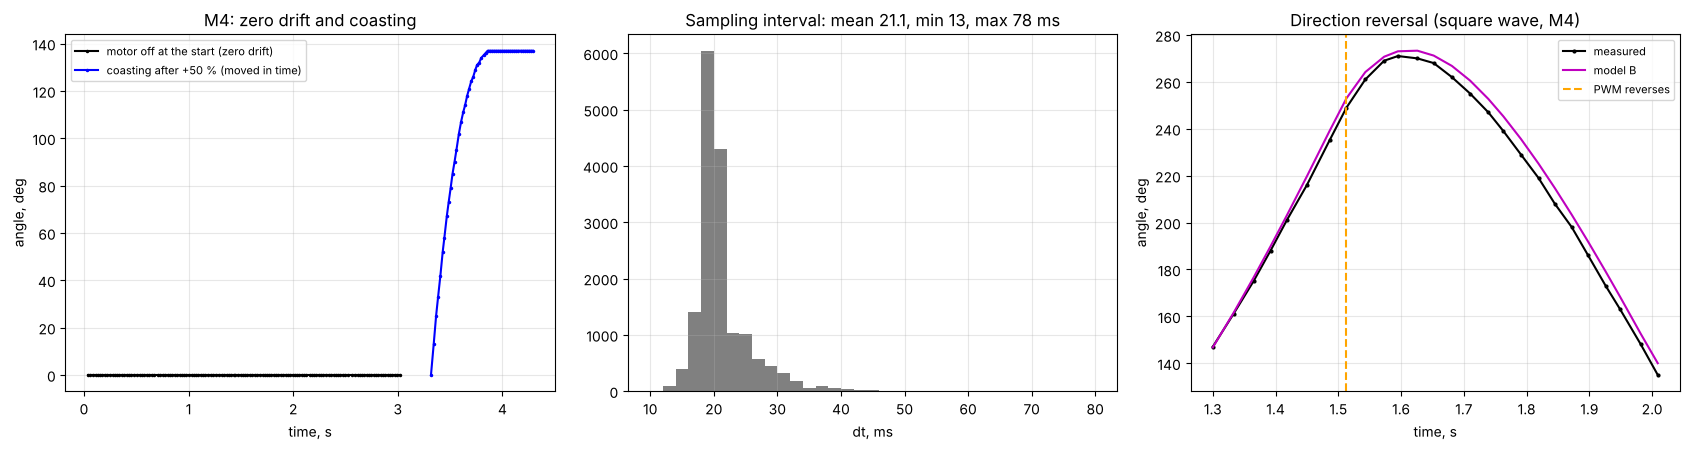

steps_M4.txt    sampling interval: mean 20.5 ms, min 13 ms, max 52 ms
square_M4.txt   sampling interval: mean 27.6 ms, min 16 ms, max 78 ms


In [14]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))

angle, t, pwm = load('steps_M4.txt')
first_on = np.where(pwm != 0)[0][0]
axs[0].plot(t[:first_on], np.degrees(angle[:first_on]), 'k.-', ms=3, label='motor off at the start (zero drift)')
i, j = after_step(pwm, 50)
axs[0].plot(t[i:j] - t[i] + t[first_on - 1] + 0.3, np.degrees(angle[i:j] - angle[i]), 'b.-', ms=3,
            label='coasting after +50 % (moved in time)')
axs[0].set_title('M4: zero drift and coasting')
axs[0].set_xlabel('time, s')
axs[0].set_ylabel('angle, deg')
axs[0].legend(fontsize=8)
axs[0].grid(alpha=0.3)

files = ['steps_M4.txt', 'steps_M4_repeat.txt', 'steps_M3.txt', 'deadzone_M4.txt', 'deadzone_M3.txt',
         'square_M4.txt', 'square_M3.txt', 'chirp_M4.txt', 'chirp_M3.txt']
dts = np.concatenate([np.diff(load(name)[1]) * 1000 for name in files])
axs[1].hist(dts, bins=np.arange(10, 82, 2), color='grey')
axs[1].set_title(f'Sampling interval: mean {dts.mean():.1f}, min {dts.min():.0f}, max {dts.max():.0f} ms')
axs[1].set_xlabel('dt, ms')
axs[1].grid(alpha=0.3)

r = results['square_M4.txt']
rev = np.where(np.diff(np.sign(r['pwm'])) != 0)[0] + 1
i = rev[2]
m = (r['t'] > r['t'][i] - 0.25) & (r['t'] < r['t'][i] + 0.5)
axs[2].plot(r['t'][m], np.degrees(r['th'][m]), 'k.-', ms=4, label='measured')
axs[2].plot(r['t'][m], np.degrees(r['thB'][m]), 'm-', label='model B')
axs[2].axvline(r['t'][i], color='orange', ls='--', label='PWM reverses')
axs[2].set_title('Direction reversal (square wave, M4)')
axs[2].set_xlabel('time, s')
axs[2].set_ylabel('angle, deg')
axs[2].legend(fontsize=8)
axs[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

for name in ['steps_M4.txt', 'square_M4.txt']:
    d = np.diff(load(name)[1]) * 1000
    print(f'{name:15s} sampling interval: mean {d.mean():.1f} ms, min {d.min():.0f} ms, max {d.max():.0f} ms')

In [15]:
print('Backlash: time from the PWM reversal to the turning point of the angle')
for name in ['square_M4.txt', 'square_M3.txt']:
    r = results[name]
    rev = np.where(np.diff(np.sign(r['pwm'])) != 0)[0] + 1
    d_meas, d_model = [], []
    for i in rev[1:]:
        idx = np.where((r['t'] >= r['t'][i - 1]) & (r['t'] < r['t'][i] + 0.4))[0]
        sign = np.sign(r['pwm'][i - 1])
        d_meas.append(r['t'][idx[np.argmax(sign * r['th'][idx])]] - r['t'][i - 1])
        d_model.append(r['t'][idx[np.argmax(sign * r['thB'][idx])]] - r['t'][i - 1])
    print(f'  {name}: measured {1000 * np.mean(d_meas):.0f} ms, model {1000 * np.mean(d_model):.0f} ms')

Backlash: time from the PWM reversal to the turning point of the angle
  square_M4.txt: measured 124 ms, model 143 ms
  square_M3.txt: measured 132 ms, model 155 ms


In [16]:
print('Battery sag: the display showed 11.2 V before and after every run (motor_data/battery.txt)')

w1, e1, T1, Te1 = steps['M4']
w2, e2, T2, Te2 = steps['M4 repeat']
dw = 100 * (w2 / w1 - 1)
big = np.abs(np.array(levels)) > 20
print(f'Repeatability, M4 run 2 vs run 1: w_ss {dw.mean():+.1f} % on average (from {dw.min():+.1f} to {dw.max():+.1f} %), '
      f'above 20 % at most {np.abs(dw[big]).max():.1f} %')
print(f'  T_m: difference from {(T2 - T1).min():+.3f} to {(T2 - T1).max():+.3f} s, '
      f'while the standard error of one fit is only {np.median(Te1):.3f} s')

ts, th = cut('steps_M4.txt', 50)
w_raw = np.gradient(th, ts)
last = ts > 1
print(f'Speed noise at +50 % (last 1 s): raw gradient std {w_raw[last].std():.2f} rad/s, '
      f'after the moving average of 5: {smooth(w_raw)[last][WINDOW:-WINDOW].std():.2f} rad/s; '
      f'one encoder step (1 deg) in one sample = {np.radians(1) / np.mean(np.diff(ts)):.2f} rad/s')

Battery sag: the display showed 11.2 V before and after every run (motor_data/battery.txt)
Repeatability, M4 run 2 vs run 1: w_ss +0.3 % on average (from -3.7 to +6.7 %), above 20 % at most 3.7 %
  T_m: difference from -0.120 to +0.188 s, while the standard error of one fit is only 0.001 s
Speed noise at +50 % (last 1 s): raw gradient std 0.38 rad/s, after the moving average of 5: 0.17 rad/s; one encoder step (1 deg) in one sample = 0.87 rad/s


## 6. Report

### 6.1 Estimated values

**Left wheel — motor M4, encoder E4**

| Direction | Dead zone, % PWM | Slope, rad/s per % PWM | $k_e$, V·s/rad | Mean $T_m$, s | $U_{battery}$, V |
|---|---|---|---|---|---|
| Forward | none (moves from 1 %) | 0.116 | 0.97 | 0.15 ± 0.08 | 11.2 |
| Backward | 1 … 4 % (moves from 5 %) | 0.106 | 1.05 | 0.18 ± 0.10 | 11.2 |

Repeated run on M4: forward 0.115 rad/s per %, $k_e$ = 0.98, $T_m$ = 0.18 s; backward 0.109, $k_e$ = 1.03, $T_m$ = 0.17 s.

**Right wheel — motor M3, encoder E3**

| Direction | Dead zone, % PWM | Slope, rad/s per % PWM | $k_e$, V·s/rad | Mean $T_m$, s | $U_{battery}$, V |
|---|---|---|---|---|---|
| Forward | none (moves from 1 %) | 0.094 | 1.19 | 0.21 ± 0.11 | 11.2 |
| Backward | none (moves from 1 %) | 0.092 | 1.22 | 0.19 ± 0.11 | 11.2 |

Slope and $k_e$ come from the linear part ($|\text{PWM}| \ge 30\%$). The fitted line does not pass through zero: its offset is +3.1 … 3.4 rad/s for M4 and +5.2 … 5.5 rad/s for M3. $T_m$ is the mean ± standard deviation over the ten levels of one direction; it falls from about 0.3 s at 10 % to about 0.05 s at 100 %.

**Complex signals, model B (dead zone + line of each direction + mean $T_m$)**

| Signal | Speed fit | Angle fit | RMSE speed, rad/s | RMSE angle, rad |
|---|---|---|---|---|
| Square, M4 | 90.9 % | 53.6 % | 0.50 | 0.57 |
| Square, M3 | 85.9 % | 64.7 % | 0.85 | 0.56 |
| Chirp, M4 | 62.4 % | −5.2 % | 1.19 | 1.33 |
| Chirp, M3 | 64.9 % | −95.8 % | 1.11 | 2.19 |

### 6.2 Analysis

**How well does the first-order model describe the motor?** Every single step fits the first-order curve very well (in plot 1 the dots lie on the fitted line), but one constant $k_e$ and $T_m$ for the whole range is not enough. The speed is linear in PWM only above about 30 % and the line does not go through zero, so the simple model $\omega_{ss} = U/k_e$ is 30–50 % too slow at 60 %. With the dead zone and a separate line for each direction (model B) the speed fit on the square wave is 91 % for the left wheel and 86 % for the right wheel, but only 62–65 % on the chirp. On the chirp the error is largest in two places: in the first second, when the wheel starts from rest slower than the model (the measured angle is already 0.9–1.6 rad behind), and after about 4 s (above about 2.5 Hz), where the measured speed swings more than the model and the difference reaches 4 rad/s. $T_m$ is not constant either: it falls from about 0.3 s at 10 % to 0.05 s at 100 % and changed by up to 0.19 s between two runs, so it is the weakest number of the model.

**Forward vs backward.** For the left motor (M4) the two directions are different: backward the slope is 8 % smaller, the mean $T_m$ is 17 % larger, and there is a small dead zone (−1 … −4 %) that forward does not have. For the right motor (M3) the difference is only 3–4 %. So a controller should use two sets of parameters at least for M4; for M3 one set is almost enough.

**Artifacts.** I found no zero drift: with the motor off the encoder stayed at 0 for 3 s. The dead zone exists only for M4 backward (1–4 %), and I did not see saturation or gear backlash. The biggest effects are coasting and the difference between the motors: after 100 % the wheel still turns 3.4 rad (M4) and 5.5 rad (M3), because PWM = 0 does not brake, and the right wheel is 11–18 % faster at 50 %. The sampling interval is 21 ms on average (13–78 ms) because the file is written every cycle, and the battery stayed at 11.2 V. For odometry the motor difference and the coasting matter most: with the same PWM the robot curves to the left and keeps moving after the stop, so the position has to be computed from the encoders, not from the PWM.

**Which complex signals and what they showed.** I used a square wave and a chirp. The square wave showed fast direction reversals from +60 % to −60 % and no backlash, and the model works best on it (speed fit 86–91 %). The chirp gave the frequency response: the speed amplitude falls from about 1.3 rad/s per V at 0.7 Hz to about 0.3 at 5 Hz, and it follows the first-order curve only if $k_e$ is taken at the signal amplitude, which shows again that the motor gain depends on the amplitude.
